# QuantumScreen - walkthrough
**Quantum computing-based drug screening for BACE-1 (Alzheimer's target) with Qiskit.**

This notebook runs the pipeline step by step: data -> fingerprints -> qubit encoding -> quantum kernel -> SVM ->
comparison with classical models -> candidate ranking -> VQE demo. The full benchmark (repeated seeds, ablations, VQC) is
produced by `python main.py`; see `results/` and `docs/RESULTS.md`.

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from quantumscreen.config import Config
from quantumscreen.data import load_bace, stratified_split
from quantumscreen.features import morgan_matrix, drug_likeness, QuantumEncoder
from quantumscreen.quantum import (build_feature_map, compute_states, fidelity_kernel, fit_qsvm_tuned)
from quantumscreen.classical import fit_rbf_svm, fit_random_forest
from quantumscreen.ranking import rank_candidates
cfg = Config()

## 1. Data
BACE-1 inhibitors (MoleculeNet): SMILES + active/inactive label.

In [2]:
df = load_bace("../data/bace.csv")
print(len(df), "molecules;", f"{df.label.mean():.1%} active")
df.head()

1513 molecules; 45.7% active


,cid,smiles,label,pIC50
0,BACE_1,Cc1ccccc1-c1ccc2nc(N)c(C[C@@H](C)C(=O)N[C@@H]3...,1,9.154901
1,BACE_2,CCCO[C@H]1C[NH2+][C@@H]([C@@H](O)[C@H](Cc2cc(F...,1,8.853872
2,BACE_3,CCc1cn2c3c(cc(C(=O)N[C@@H](Cc4ccccc4)[C@H](O)C...,1,8.698970
3,BACE_4,CCOC[C@@H](Oc1cc(C[C@@H]2CS(=O)(=O)C[C@H]([NH2...,1,8.698970
4,BACE_5,CCc1cn2c3c(cc(C(=O)N[C@@H](Cc4ccccc4)[C@H](O)C...,1,8.698970


## 2. Drug-likeness (RDKit)
Lipinski's rule of five and QED. Most molecules in this dataset already pass the rule, so it is used as a *soft* penalty in the ranking.

In [3]:
props = drug_likeness(df.smiles)
print("Pass Lipinski (<=1 violation): actives %.0f%%, inactives %.0f%%" % (
    100*props.loc[df.label==1, "passes_lipinski"].mean(), 100*props.loc[df.label==0, "passes_lipinski"].mean()))
props.groupby(df.label)[["MW", "LogP", "HBD", "HBA", "QED"]].mean().round(2)

Pass Lipinski (<=1 violation): actives 95%, inactives 97%


,MW,LogP,HBD,HBA,QED
label,,,,,
0,448.77,3.10,2.29,4.40,0.57
1,516.43,3.16,2.61,5.05,0.46


## 3. Molecules to qubits
Morgan fingerprint (2048 bits) -> PCA (8 components) -> rotation angles in [0, pi]; one component per qubit.

In [4]:
Xfp = morgan_matrix(df.smiles); y = df.label.values
tr, te = stratified_split(df, cfg.test_size, seed=0)
enc = QuantumEncoder(cfg.n_qubits).fit(Xfp[tr])
Xtr, Xte = enc.transform(Xfp[tr]), enc.transform(Xfp[te])
print("variance kept by 8 PCA components: %.1f%%" % (100*enc.pca_.explained_variance_ratio_.sum()))
print(Xtr[:2].round(2))

variance kept by 8 PCA components: 36.4%
[[1.27 1.53 1.55 0.5  2.34 0.84 1.13 1.35]
 [2.4  1.34 2.5  1.12 2.9  0.07 1.11 2.89]]


## 4. The quantum feature map
A ZZ feature map: Hadamards, single-qubit Z rotations by the data, and entangling ZZ rotations between neighbours.

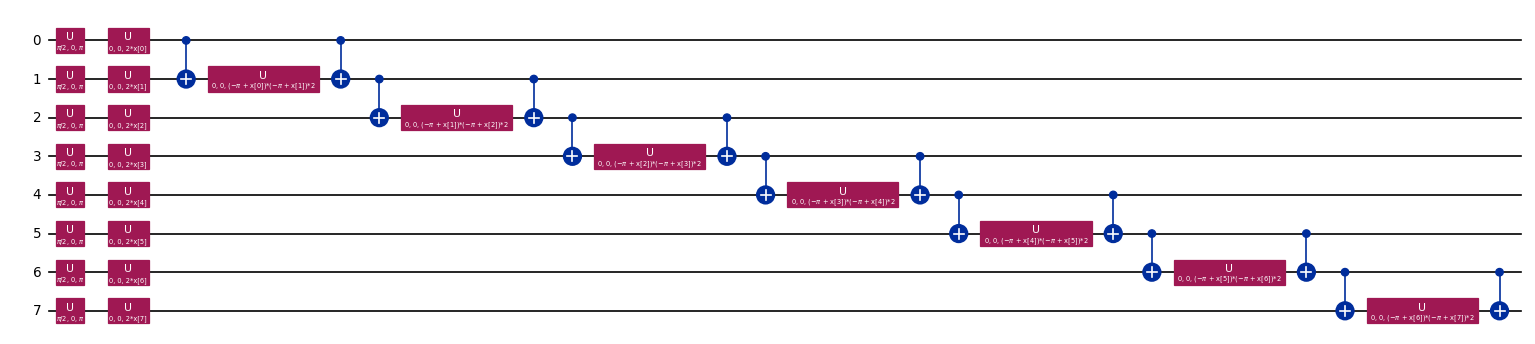

In [5]:
fm = build_feature_map("zz", cfg.n_qubits, reps=1)
fm.decompose().draw("mpl", fold=40, scale=0.6)

## 5. Quantum kernel
`k(x, x') = |<phi(x)|phi(x')>|^2` (rows/columns sorted by class). The bright diagonal is each molecule compared with itself; off-diagonal brightness marks similar molecules. Most pairs are nearly orthogonal (dark) - a known 'kernel concentration' effect of high-dimensional quantum feature spaces, and the reason a small angle scale (0.25) is selected by cross-validation.

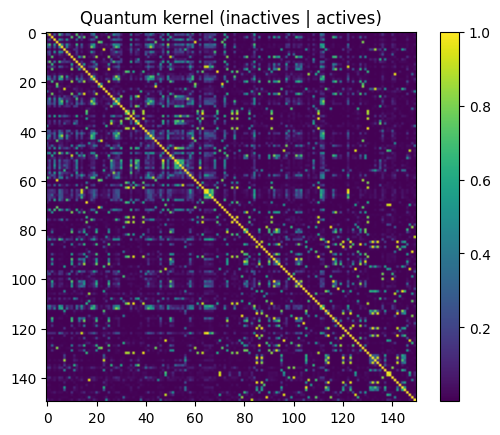

In [6]:
circuit = build_feature_map(cfg.feature_map, cfg.n_qubits, cfg.reps)
idx = np.random.default_rng(0).choice(len(Xte), 150, replace=False)
S = compute_states(circuit, Xte[idx] * 0.25)
K = fidelity_kernel(S, S); order = np.argsort(y[te][idx])
plt.imshow(K[np.ix_(order, order)], cmap="viridis"); plt.colorbar(); plt.title("Quantum kernel (inactives | actives)"); plt.show()

## 6. Train quantum kernel SVM vs classical baselines
(C, scale) are tuned by inner cross-validation on the training split only.

best quantum params: {'scale': 0.25, 'C': 10.0, 'cv_auc': np.float64(0.8522980842665179)}


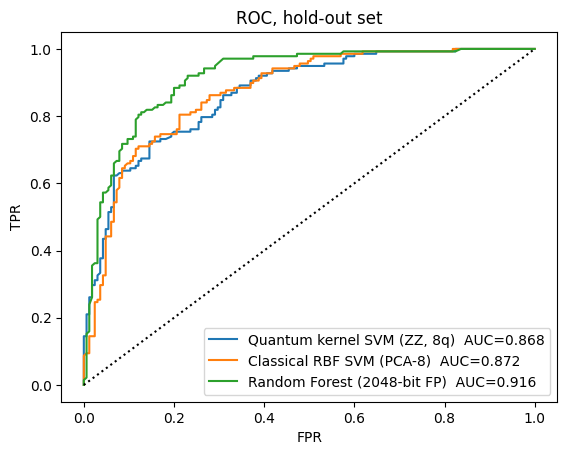

In [7]:
qsvm, cv = fit_qsvm_tuned(Xtr, y[tr], cfg.feature_map, cfg.reps, cfg.c_grid, cfg.scale_grid, cfg.cv_folds, 0)
svm, _ = fit_rbf_svm(Xtr, y[tr], cfg.c_grid, cfg.cv_folds, 0)
rf = fit_random_forest(Xfp[tr], y[tr], 0)
scores = {"Quantum kernel SVM (ZZ, 8q)": qsvm.predict_proba(Xte)[:, 1],
          "Classical RBF SVM (PCA-8)": svm.predict_proba(Xte)[:, 1],
          "Random Forest (2048-bit FP)": rf.predict_proba(Xfp[te])[:, 1]}
print("best quantum params:", qsvm.best_params_)
for k, s in scores.items():
    fpr, tpr, _ = roc_curve(y[te], s); plt.plot(fpr, tpr, label=f"{k}  AUC={roc_auc_score(y[te], s):.3f}")
plt.plot([0, 1], [0, 1], "k:"); plt.legend(); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC, hold-out set"); plt.show()

## 7. Rank the hold-out library
`final_score = 0.7*P(active) + 0.3*QED - penalty for Lipinski violations beyond one`.

In [8]:
ranked = rank_candidates(df.iloc[te], scores["Quantum kernel SVM (ZZ, 8q)"], cfg)
top = ranked.head(25)
print("hit-rate in top 25: %.0f%%  (library base rate %.0f%%)" % (100*top.known_label.mean(), 100*y[te].mean()))
ranked[["rank", "smiles", "known_label", "p_quantum_active", "QED", "lipinski_violations", "final_score"]].head(10)

hit-rate in top 25: 92%  (library base rate 46%)


,rank,smiles,known_label,p_quantum_active,QED,lipinski_violations,final_score
0,1,N#Cc1ccc(C(=O)Nc2ccc(F)c([C@@]3(CF)N=C(N)OC[C@...,1,0.860388,0.832237,0,0.851942
1,2,CCCC#Cc1cccc([C@@]2(c3ccc(OC(F)F)cc3)N=C(N)N(C...,1,0.850115,0.785909,0,0.830853
2,3,CN1C(=O)[C@@](c2ccc(OC(F)F)cc2)(c2cccc(C#CCCF)...,1,0.848934,0.783534,0,0.829314
3,4,CN1C(=O)[C@@](c2ccc(OC(F)F)cc2)(c2cccc(C#CC3CC...,1,0.824564,0.809377,0,0.820008
4,5,CC(C)Oc1cc(CC2CS(=O)(=O)CC([NH2+]Cc3cccc(C(C)(...,1,0.940657,0.514285,0,0.812746
5,6,CN1C(=O)[C@@](c2ccc(OC(F)F)cc2)(c2cccc(/C=C/CC...,1,0.825255,0.766773,0,0.807711
6,7,Cc1ccccc1-c1ccc2nc(N)c(CC(C)C(=O)NCC3CCCCC3)cc2c1,1,0.914758,0.545111,1,0.803864
7,8,CN1C(=O)C(c2cccc(-c3cccnc3F)c2)(c2cnn(C3CCCC3)...,1,0.865859,0.659007,0,0.803803
8,9,COc1ccc([C@]2(c3cccc(-c4cccnc4F)c3)N=C(N)N(C)C...,1,0.848010,0.694836,0,0.802058
9,10,Cc1cc([C@]2(c3ccc(F)c(C#CCF)c3)N=C(N)N(C)C2=O)...,1,0.878368,0.611919,0,0.798434


## 8. Choose a diverse batch with QAOA
A lab can advance only K of the shortlisted molecules. Maximise `J(x) = sum s_i x_i - lambda * sum S_ij x_i x_j` (score minus Tanimoto redundancy; no experimental affinity is used) subject to a budget of K, as a QUBO -> Ising Hamiltonian solved by QAOA, and compare with classical solvers.

In [9]:
from quantumscreen.selection import (SelectionProblem, tanimoto_matrix, solve_exact, solve_topk, solve_greedy_diverse, QAOASolver)
top = ranked.head(10)
prob = SelectionProblem(top.final_score.values, tanimoto_matrix(top.smiles), k=3, lam=0.5)
_, j_opt = solve_exact(prob)
res = QAOASolver(prob, p=2, restarts=3, maxiter=60, shots=1024, seed=0).run()
print(f"exact optimum J = {j_opt:.3f}")
print(f"top-K by score   : {solve_topk(prob)[1]/j_opt:.3f} of optimum")
print(f"greedy (diverse) : {solve_greedy_diverse(prob)[1]/j_opt:.3f}")
print(f"QAOA (p=2)       : {res['approx_ratio']:.3f}  | feasible probability mass {res['feasible_mass']:.2f}"
      f" | quality vs random feasible subsets {res['quality']/res['random_quality']:.3f} (1 = no better than random)")

exact optimum J = 2.286
top-K by score   : 0.847 of optimum
greedy (diverse) : 1.000
QAOA (p=2)       : 1.000  | feasible probability mass 0.36 | quality vs random feasible subsets 1.002 (1 = no better than random)


Note the last number: QAOA's best sample is near-optimal, but its output distribution is no better than random sampling of feasible subsets (see `docs/RESULTS.md`).

## 9. VQE demo (quantum chemistry)
Ground-state energy of H2 with a UCCSD ansatz on 2 qubits, compared with exact diagonalisation. Requires `qiskit-nature` and `pyscf`.

In [10]:
try:
    from quantumscreen.vqe import vqe_curve
    h2 = vqe_curve("H2", (0.5, 0.74, 1.0, 1.5, 2.0))
    display(h2.round(5))
except ImportError as e:
    print("VQE skipped (install requirements-vqe.txt):", e)

,molecule,bond_length_A,n_qubits,n_parameters,E_hf,E_exact,E_vqe,error_mHa
0,H2,0.50,2,3,-1.04300,-1.05516,-1.05516,0.00000
1,H2,0.74,2,3,-1.11676,-1.13728,-1.13728,0.00000
2,H2,1.00,2,3,-1.06611,-1.10115,-1.10115,0.00001
3,H2,1.50,2,3,-0.91087,-0.99815,-0.99815,0.00000
4,H2,2.00,2,3,-0.78379,-0.94864,-0.94864,0.00000


## Conclusions
* The pipeline is fully reproducible and runs on a laptop CPU.
* Quantum-kernel SVM performance is **comparable to, not better than,** a tuned classical RBF SVM on the same 8 features.
* Entanglement did not help (the un-entangled `z` map scores the same as `zz`), and a Random Forest on the full fingerprint
  beats every model that sees only 8 PCA features: the bottleneck is the 2048 -> 8 compression, not the kernel.
* QAOA picks near-optimal diverse batches, but random search with the same shots does equally well.
* VQE reproduces exact H2/LiH energies to well below chemical accuracy.